# 05-2. 결빙 위험도 기준표와 지도

05의 3~6장입니다. 기상, 도로, 지형 요인별 위험 수준(1~4)과 근거를 기준표로 만들고, 구간별 점수와 등급(관심, 주의, 경계, 심각)을 계산합니다. 기존 결빙취약구간 22개소와 비교한 뒤 지도(jpg, png, html)와 shapefile로 저장합니다.

02-2의 구간·지점 정보, 05-1의 구간별 추정값과 결빙 가능 조건, 04-1의 모델 정보(`model/icing_meta.json`), 02-3의 구간 ERA5-Land(`segment_era5_1h.parquet`)를 읽습니다. 지도는 `figures/risk_map.*`, `figures/risk_map_vulnerable.jpg`, `figures/risk_map_shp/`에, 기준표와 구간별 위험도는 `data/results/`에 저장합니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import warnings

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from cycler import cycler
from matplotlib import font_manager
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
GRADES = ["관심", "주의", "경계", "심각"]
GRADE_COLORS = {"관심": "#0ca30c", "주의": "#fab219", "경계": "#ec835a", "심각": "#d03b3b"}
N_WINTERS = len(config.PERIODS)

In [3]:
segments = gpd.read_file(config.PROCESSED_DIR / "segments.gpkg")
seg_feat = pd.read_parquet(config.PROCESSED_DIR / "segment_features.parquet").merge(
    pd.read_parquet(config.PROCESSED_DIR / "segment_estimates.parquet"), on=["seg_id", "time"], how="left",
    validate="one_to_one")  # 05-1의 구간별 추정값 (rst_est, rst_dpd, p_icing)
seg_summary = pd.read_parquet(config.PROCESSED_DIR / "segment_summary.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
station_seg = pd.read_csv(config.PROCESSED_DIR / "station_segment_match.csv")
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet").merge(
    pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
cls_meta = json.load(open(config.MODEL_DIR / "icing_meta.json", encoding="utf-8"))
seg_era5_path = config.PROCESSED_DIR / "segment_era5_1h.parquet"  # 02-3: 구간이 쓰는 ERA5 격자를 모두 받았을 때만 있다
USE_M3 = seg_era5_path.exists()
if USE_M3:
    seg_feat = seg_feat.merge(pd.read_parquet(seg_era5_path, columns=["seg_id", "time", "sf_mmh"]),
                              on=["seg_id", "time"], how="left", validate="one_to_one")

# 05-1(2장)에서 정한 결빙 가능 환경조건
cond = json.load(open(config.PROCESSED_DIR / "icing_conditions.json", encoding="utf-8"))
T_RST, T_RH = cond["T_RST"], cond["T_RH"]
conditions = pd.DataFrame.from_dict(cond["conditions"], orient="index")
corr = pd.DataFrame(cond["station_corr"])


def icing_condition(df, rst_col="rst"):
    """결빙 가능 환경조건: 저온 + 고습 + 수분 공급 (05-1의 2장과 같은 정의)."""
    moist = (df["rain_hrs12h"] > 0) | (df["snow"] > 0) | ((df[rst_col] - df["td"]) <= 0)
    return (df[rst_col] <= T_RST) & (df["rh"] >= T_RH) & moist


print(f"구간 {len(segments)}개, 구간 시계열 {seg_feat.shape[0]:,}행 (1시간 간격)")
print(f"결빙 가능 조건: 노면온도 ≤ {T_RST}°C, 습도 ≥ {T_RH:.0f}%, 수분 공급")
print("기상 지표 M3(ERA5 강설):", "사용" if USE_M3 else "구간 ERA5 자료가 없어 쓰지 않음 (02-3의 6-3)")

구간 233개, 구간 시계열 1,342,080행 (1시간 간격)
결빙 가능 조건: 노면온도 ≤ 1.0°C, 습도 ≥ 70%, 수분 공급
기상 지표 M3(ERA5 강설): 사용


## 3. 결빙 위험도 기준표

요인별 하위 지표를 1~4 수준으로 나누고 요인 점수는 하위 지표의 평균(도로는 최댓값)으로 합니다. 문제의 평가표 항목을 모두 담지 않고 제공·공개 자료로 산정할 수 있는 요소로 새 기준을 제시했습니다(QnA 2026-11-03).

기상 요인은 구간별 추정값으로 계산한 동적 지표이고 구간 간 비교를 위해 사분위수로 수준을 나눕니다. M3(ERA5 강설 중 추정 노면온도 0°C 이하인 시간)는 구간이 쓰는 ERA5 격자 25개를 모두 받아서 씁니다(02-3의 6-3). 도로 요인은 교량과 터널 입출구, 지형 요인은 표고, 겨울 지형 그늘, 하천 인접·골짜기입니다.

요인별 근거는 다음과 같습니다(01-1의 0장, 01-6·01-7의 13장).

| 요인 | 이론 | 이 자료에서 확인한 내용 |
|------|------|------------------------|
| 교량 | 교량 노면은 일반 도로보다 1~2°C 낮다 (Tabatabai & Aljuboori 2017; Rathke & McPherson 2006). 모든 교량이 그렇지는 않다 (김유정 외 2023) | 우곡3교는 밤 -1.6°C, 부곡교는 +0.6°C. 지점마다 다름 (13-7) |
| 터널 입출구 | 입·출구 부근 노면온도 급변 (김유정 외 2023), 터널 입구는 블랙아이스 취약 장소 (Hong et al. 2022) | 고정 관측소 1곳뿐이라 확인 불가 (13-8) |
| 표고 | 기온감률 약 6.5°C/km, 대기 안정도에 따라 0~9°C/km (Chapman et al. 2001) | 산 정상을 뺀 AWS 밤 감률 0.73~0.82°C/100m로 안정도와 거의 무관 (13-5) |
| 지형 그늘 | 차폐가 낮 동안 노면 가열을 줄인다 (Chapman et al. 2001) | 겨울 지형 그늘과 맑은 한낮 노면 편차 순위상관 -0.38 (13-6) |
| 하천·골짜기 | 골짜기 바닥의 찬 공기 고임(냉기호), 안개·수증기 응결 (Chapman et al. 2001; Zerr 1997) | 안정한 밤일수록 표고로 설명되지 않는 지점 차가 커짐 (13-5) |

교량·터널 효과는 지점마다 달라서 도로 요인에 총점의 1/4만 주고, 결빙의 직접 원인인 기상 요인에 절반을 줬습니다. 곡선 반경과 종단경사는 기존 평가표의 기하구조 분야가 이미 점수화해서 총점에 넣지 않았습니다(근거와 민감도는 4장).

총점 = 0.5 x 기상 + 0.25 x 도로 + 0.25 x 지형 (1~4점)입니다. 가중치 민감도는 4장에서 확인합니다.

In [4]:
seg = segments.set_index("seg_id").join(seg_summary)
seg["icing_cond_hours"] = (seg_feat.assign(c=icing_condition(seg_feat, rst_col="rst_est"))
                           .groupby("seg_id")["c"].sum() / N_WINTERS)
seg["icing_pred_hours"] = (seg_feat.assign(c=seg_feat["p_icing"] >= cls_meta["threshold"])
                           .groupby("seg_id")["c"].sum() / N_WINTERS)
if USE_M3:  # ERA5 강설 0.05 mm/h 이상 & 추정 노면 0°C 이하 (05-1의 2장 관측소 지표와 같은 정의)
    seg["frz_snow_hours"] = (seg_feat.assign(c=(seg_feat["sf_mmh"] > 0.05) & (seg_feat["rst_est"] <= 0))
                             .groupby("seg_id")["c"].sum() / N_WINTERS)
seg["tunnel_portal"] = (seg["seg_dist_tunnel"] <= 300) & (seg["tunnel_ratio"] < 0.9)


def quartile_level(x):
    q = x.quantile([0.25, 0.5, 0.75]).to_numpy()
    return pd.Series(np.digitize(x, q, right=True) + 1, index=x.index), q


def cut_level(x, bins):
    return pd.Series(np.digitize(x, bins, right=False) + 1, index=x.index).clip(1, 4)


lv = pd.DataFrame(index=seg.index)
lv["M1"], q_m1 = quartile_level(seg["icing_cond_hours"])
lv["M2"], q_m2 = quartile_level(seg["icing_pred_hours"])
if USE_M3:
    lv["M3"], q_m3 = quartile_level(seg["frz_snow_hours"])
lv["R1"] = cut_level(seg["bridge_ratio"], [1e-9, 0.1, 0.3])
lv["R2"] = np.select([seg["tunnel_ratio"] >= 0.9, seg["tunnel_portal"], seg["seg_dist_tunnel"] <= 1000], [1, 3, 2], 1)
lv["T1"] = cut_level(seg["elev"], [100, 250, 400])
lv["T2"] = cut_level(seg["shade_winter"], [0.02, 0.05, 0.10])
lv["T3"] = np.select([(seg["dist_river"] <= 100) | (seg["tpi"] <= -30),
                      (seg["dist_river"] <= 300) | (seg["tpi"] <= -10)], [3, 2], 1)

criteria_rows = [
    ["기상", "M1 결빙 가능 시간 (h/겨울)", f"≤{q_m1[0]:.0f}", f"{q_m1[0]:.0f}~{q_m1[1]:.0f}", f"{q_m1[1]:.0f}~{q_m1[2]:.0f}",
     f">{q_m1[2]:.0f}",
     f"추정 노면온도 ≤ {T_RST}°C, 습도 ≥ {T_RH:.0f}%, 수분 공급(강수·적설·서리)인 시간. "
     f"학습 지점 Ice의 {conditions.iloc[-1]['Ice 포착률']:.0%}를 포함하고 평균 대비 {conditions.iloc[-1]['향상도(lift)']:.1f}배. "
     "결빙 = 수분 + 어는점 이하 노면 (Zerr 1997), 강수 시 노면 1°C 미만 결빙 (Bonanno et al. 2010)"],
    ["기상", "M2 결빙관련 노면 예측 시간 (h/겨울)", f"≤{q_m2[0]:.0f}", f"{q_m2[0]:.0f}~{q_m2[1]:.0f}",
     f"{q_m2[1]:.0f}~{q_m2[2]:.0f}", f">{q_m2[2]:.0f}",
     f"04 분류 모델 확률 ≥ {cls_meta['threshold']:.2f}인 시간 (Snow·Ice·결빙시작·판별불가 노면)"],
    ["도로", "R1 교량 구간 비율", "0", "0~10%", "10~30%", ">30%",
     "교량 상판은 위아래로 공기에 노출되어 노면이 빨리 식습니다. 교량 노면은 일반 도로보다 1~2°C 낮습니다 "
     "(Tabatabai & Aljuboori 2017; Rathke & McPherson 2006). 관측소에서도 교량에 가까울수록 노면 0°C 이하 비율이 높습니다. "
     "교량마다 차이가 커서(우곡3교 -1.6°C, 부곡교 +0.6°C) 도로 요인 안에서만 반영했습니다"],
    ["도로", "R2 터널 입출구", "터널 안(90% 이상)·해당 없음", "터널 1km 이내", "입출구 300m 이내", "-",
     "터널 입출구는 그늘이 지고 터널 안팎의 온도·노면 습윤 차이가 커서 결빙이 잦습니다. "
     "입·출구 부근 노면온도 급변 (김유정 외 2023), 터널 입구는 블랙아이스 취약 장소 (Hong et al. 2022)"],
    ["지형", "T1 표고", "<100m", "100~250m", "250~400m", "≥400m",
     f"기온감률(약 0.65°C/100m, Chapman et al. 2001). 관측소 노면 0°C 이하 비율과 순위상관 {corr.loc['표고', '노면0도이하비율']:.2f}"],
    ["지형", "T2 겨울 지형 그늘 비율", "<2%", "2~5%", "5~10%", "≥10%",
     f"동지 무렵 직달 일사 중 산에 가려지는 비율. 차폐가 낮 동안 노면 가열을 줄입니다 (Chapman et al. 2001). "
     f"노면 0°C 이하 비율과 순위상관 {corr.loc['겨울 지형 그늘', '노면0도이하비율']:.2f}"],
    ["지형", "T3 하천 인접·골짜기", "해당 없음", "하천 300m 이내 또는 TPI ≤ -10m", "하천 100m 이내 또는 TPI ≤ -30m", "-",
     "하천 주변은 습도가 높고 안개가 잦으며(수증기 응결, Zerr 1997), 골짜기는 밤에 찬 공기가 고입니다 (냉기호, Chapman et al. 2001)"],
]
if USE_M3:
    m3, aws = corr.loc["ERA5 강설 & 추정 노면 ≤ 0°C"], corr.loc["AWS 강수 감지 & 추정 노면 ≤ 0°C"]
    criteria_rows.insert(2, [
        "기상", "M3 영하 노면 강설 시간 (h/겨울)", f"≤{q_m3[0]:.0f}", f"{q_m3[0]:.0f}~{q_m3[1]:.0f}",
        f"{q_m3[1]:.0f}~{q_m3[2]:.0f}", f">{q_m3[2]:.0f}",
        f"ERA5-Land 강설(물 환산 0.05 mm/h 이상) 중 추정 노면온도 ≤ 0°C인 시간. 눈이 언 노면에 내리는 시간 (수분 + 어는점 이하 노면). "
        f"관측소 단위 순위상관: Ice 비율 {m3['Ice비율']:.2f}, 결빙관련 비율 {m3['결빙관련비율']:.2f} "
        f"(AWS 강수 감지로 만든 같은 지표는 {aws['Ice비율']:.2f}, {aws['결빙관련비율']:.2f}, 05-1의 2장)"])
criteria = pd.DataFrame(criteria_rows, columns=["요인", "지표", "수준1", "수준2", "수준3", "수준4", "기준 설정 근거"])
criteria.loc[criteria["요인"] == "기상", "기준 설정 근거"] += f". 수준은 구간 {len(seg)}개의 사분위수"
criteria

,요인,지표,수준1,수준2,수준3,수준4,기준 설정 근거
0,기상,M1 결빙 가능 시간 (h/겨울),≤264,264~288,288~338,>338,"추정 노면온도 ≤ 1.0°C, 습도 ≥ 70%, 수분 공급(강수·적설·서리)인 시간..."
1,기상,M2 결빙관련 노면 예측 시간 (h/겨울),≤22,22~28,28~38,>38,04 분류 모델 확률 ≥ 0.73인 시간 (Snow·Ice·결빙시작·판별불가 노면)...
2,기상,M3 영하 노면 강설 시간 (h/겨울),≤50,50~70,70~91,>91,ERA5-Land 강설(물 환산 0.05 mm/h 이상) 중 추정 노면온도 ≤ 0°...
3,도로,R1 교량 구간 비율,0,0~10%,10~30%,>30%,교량 상판은 위아래로 공기에 노출되어 노면이 빨리 식습니다. 교량 노면은 일반 도로...
4,도로,R2 터널 입출구,터널 안(90% 이상)·해당 없음,터널 1km 이내,입출구 300m 이내,-,터널 입출구는 그늘이 지고 터널 안팎의 온도·노면 습윤 차이가 커서 결빙이 잦습니다...
5,지형,T1 표고,<100m,100~250m,250~400m,≥400m,"기온감률(약 0.65°C/100m, Chapman et al. 2001). 관측소 ..."
6,지형,T2 겨울 지형 그늘 비율,<2%,2~5%,5~10%,≥10%,동지 무렵 직달 일사 중 산에 가려지는 비율. 차폐가 낮 동안 노면 가열을 줄입니다...
7,지형,T3 하천 인접·골짜기,해당 없음,하천 300m 이내 또는 TPI ≤ -10m,하천 100m 이내 또는 TPI ≤ -30m,-,"하천 주변은 습도가 높고 안개가 잦으며(수증기 응결, Zerr 1997), 골짜기는..."


In [5]:
WEIGHTS = {"기상": 0.5, "도로": 0.25, "지형": 0.25}


def score_segments(levels, weights=WEIGHTS):
    """구간별 요인 점수, 총점(1~4), 등급."""
    out = pd.DataFrame(index=levels.index)
    out["기상"] = levels[[m for m in ("M1", "M2", "M3") if m in levels]].mean(axis=1).round(6)  # 1/3 단위의 소수 오차를 없앤다
    out["도로"] = levels[["R1", "R2"]].max(axis=1)
    out["지형"] = levels[["T1", "T2", "T3"]].mean(axis=1).round(6)
    out["총점"] = sum(out[k] * w for k, w in weights.items()).round(6)  # 경계값 2.5가 2.4999...가 되어 등급이 내려가지 않게 한다
    out["등급"] = pd.cut(out["총점"], [0, 1.75, 2.5, 3.25, 4.01], labels=GRADES, right=False)
    return out


grade_table = pd.DataFrame({"총점 범위": ["1.00~1.75", "1.75~2.50", "2.50~3.25", "3.25~4.00"],
                            "의미": ["평상시 관리", "결빙 가능 기상 시 순찰 강화", "사전 제설·제빙 우선 구간",
                                   "상시 감시·사전 살포 최우선 구간"]}, index=GRADES)
grade_table

,총점 범위,의미
관심,1.00~1.75,평상시 관리
주의,1.75~2.50,결빙 가능 기상 시 순찰 강화
경계,2.50~3.25,사전 제설·제빙 우선 구간
심각,3.25~4.00,상시 감시·사전 살포 최우선 구간


## 4. 구간별 위험도 산출

In [6]:
scores = score_segments(lv)
seg = seg.join(lv).join(scores)
print(seg["등급"].value_counts().reindex(GRADES).to_string())
pd.crosstab(seg["route"], seg["등급"]).reindex(columns=GRADES)

등급
관심     57
주의    105
경계     55
심각     16


등급,관심,주의,경계,심각
route,,,,
서해안,11,72,17,0
통영-대전중부선,0,7,25,15
호남선,46,26,13,1


In [7]:
top = seg.sort_values("총점", ascending=False).head(15)
top[["route", "elev", "bridge_ratio", "shade_winter", "icing_cond_hours", "icing_pred_hours",
     "기상", "도로", "지형", "총점", "등급"]].round(2)

,route,elev,bridge_ratio,shade_winter,icing_cond_hours,icing_pred_hours,기상,도로,지형,총점,등급
seg_id,,,,,,,,,,,
TD-004,통영-대전중부선,445.630005,0.41,0.13,518.0,44.5,3.67,4,3.33,3.67,심각
TD-014,통영-대전중부선,483.940002,0.35,0.06,530.0,40.5,3.67,4,3.33,3.67,심각
TD-026,통영-대전중부선,483.940002,0.00,0.08,611.5,39.5,4.00,3,3.33,3.58,심각
TD-002,통영-대전중부선,483.940002,0.27,0.11,539.5,45.5,3.67,3,3.67,3.50,심각
TD-003,통영-대전중부선,576.700012,0.21,0.15,586.0,50.5,4.00,3,3.00,3.50,심각
TD-015,통영-대전중부선,494.029999,0.34,0.03,543.0,39.0,3.67,4,2.67,3.50,심각
TD-027,통영-대전중부선,422.440002,0.20,0.16,576.0,38.5,3.67,3,3.67,3.50,심각
HN-001,호남선,135.100006,0.00,0.15,391.5,64.0,4.00,3,3.00,3.50,심각
TD-013,통영-대전중부선,527.299988,0.20,0.02,554.5,44.0,4.00,3,2.67,3.42,심각


관측소가 있는 구간의 총점을 그 관측소의 실제 관측 지표와 비교했습니다. 검증 지점 3곳도 포함합니다. 관측소가 17곳뿐이라 참고용입니다.

In [8]:
all_stats = sf[sf["ice"].notna()].groupby("stn").agg(
    Ice비율=("ice", "mean"),
    결빙관련비율=("state", lambda s: s.isin(cls_meta["label_states"]).mean()),
    노면0도이하비율=("rst", lambda s: (s <= 0).mean()))
HOURS = ["icing_cond_hours", "icing_pred_hours", *(["frz_snow_hours"] if USE_M3 else [])]
val = station_seg.set_index("stn")[["name", "seg_id", "holdout"]].join(all_stats)
val = val.join(seg[HOURS + ["기상", "도로", "지형", "총점", "등급"]], on="seg_id")
rho = pd.DataFrame({t: {c: spearmanr(val[c], val[t])[0] for c in HOURS + ["기상", "총점"]}
                    for t in ["Ice비율", "결빙관련비율", "노면0도이하비율"]})
rho.index = ["M1 결빙 가능 시간", "M2 결빙관련 노면 예측 시간", "M3 영하 노면 강설 시간"][:len(HOURS)] + ["기상 점수", "총점"]
print("관측소가 있는 구간 17곳의 순위상관\n", rho.round(2).to_string())
val.sort_values("총점", ascending=False).round(4)

관측소가 있는 구간 17곳의 순위상관
                   Ice비율  결빙관련비율  노면0도이하비율
M1 결빙 가능 시간       -0.18   -0.12      0.81
M2 결빙관련 노면 예측 시간   0.00    0.41      0.31
M3 영하 노면 강설 시간     0.51    0.64      0.12
기상 점수              0.04    0.31      0.51
총점                 0.02    0.06      0.63


,name,seg_id,holdout,Ice비율,결빙관련비율,노면0도이하비율,icing_cond_hours,icing_pred_hours,frz_snow_hours,기상,도로,지형,총점,등급
stn,,,,,,,,,,,,,,
33411,삼봉(도),TD-004,True,0.0000,0.0074,0.3733,518.0,44.5,81.0,3.6667,4,3.3333,3.6667,심각
23403,호남터널(도),HN-001,False,0.0014,0.0222,0.2553,391.5,64.0,97.0,4.0000,3,3.0000,3.5000,심각
33412,대곡(도),TD-002,False,0.0000,0.0116,0.3671,539.5,45.5,86.0,3.6667,3,3.6667,3.5000,심각
33410,삼가2교(도),TD-027,False,0.0000,0.0118,0.3567,576.0,38.5,81.5,3.6667,3,3.6667,3.5000,심각
33103,덕유산휴(도),TD-017,False,0.0003,0.0096,0.3482,559.5,38.0,89.5,3.3333,1,3.3333,2.7500,경계
12410,부곡교(도),SH-044,True,0.0019,0.0248,0.2116,218.5,32.5,93.5,2.6667,4,1.0000,2.5833,경계
33409,가당2교(도),TD-046,False,0.0000,0.0044,0.3317,348.0,20.5,52.0,2.3333,2,2.6667,2.3333,주의
12209,서김제(도),SH-070,False,0.0005,0.0137,0.3086,294.0,33.0,81.5,3.0000,2,1.0000,2.2500,주의
12211,고인돌휴(도),SH-021,False,0.0001,0.0145,0.2936,274.5,33.5,96.0,3.0000,1,1.3333,2.0833,주의


기상 지표 셋은 서로 다른 것을 잽니다. M1(결빙 가능 시간)은 노면 0°C 이하 비율을 따라가고(0.81) M3(영하 노면 강설 시간)는 Ice 비율(0.51)과 결빙관련 비율(0.64)을 따라갑니다. M2(결빙관련 노면 예측 시간)는 결빙관련 비율 쪽입니다(0.41). 17곳에서 5% 유의 수준은 |ρ| ≥ 0.48이므로 M3의 두 값은 넘고 M2의 0.41은 넘지 못합니다. M2는 학습 지점 14곳의 라벨로 학습한 모델의 예측이라 이 값은 낙관적일 수 있습니다.

총점은 노면 0°C 이하 비율과 순위상관이 높습니다(0.63). Ice 비율, 결빙관련 비율과는 상관이 거의 없습니다(0.02, 0.06). M3가 따라가는 Ice 빈도가 총점에서는 다른 지표에 묻힙니다. 관측된 Ice는 서해안선 일부 관측소(부안고려청자휴 등)에 몰려 있고 서해안선 관측소만 제빙제 관련 코드(12·13)를 쓰는 등 관측소마다 센서 판정 특성이 다른 것으로 보입니다.

추가 자료 ERA5-Land가 등급을 얼마나 바꾸는지 M3를 뺀 등급과 비교했습니다. 구간 등급이 격자 경계를 따라 바뀌지 않는지도 봅니다.

In [9]:
if USE_M3:
    no_m3 = score_segments(lv.drop(columns="M3"))
    moved = seg["등급"].cat.codes - no_m3["등급"].cat.codes
    print(f"M3를 넣어 등급이 바뀐 구간: {int((moved != 0).sum())}개 / {len(seg)}개")
    print("M3 제외 등급별 구간 수:", no_m3["등급"].value_counts().reindex(GRADES).to_dict())
    print(pd.crosstab(seg["route"], moved).rename(columns={-1: "한 단계 내림", 0: "그대로", 1: "한 단계 올림"}).to_string())
    base = val.drop(columns=["기상", "총점"]).join(no_m3[["기상", "총점"]], on="seg_id")
    m3_effect = pd.DataFrame({"M3 제외": {t: spearmanr(base["총점"], base[t])[0] for t in ["Ice비율", "결빙관련비율", "노면0도이하비율"]},
                              "M3 포함": {t: spearmanr(val["총점"], val[t])[0] for t in ["Ice비율", "결빙관련비율", "노면0도이하비율"]}})
    cells = pd.read_csv(config.PROCESSED_DIR / "era5_segment_cells.csv", encoding="utf-8-sig").set_index("seg_id")
    cell = cells["cell_lat"].astype(str) + "_" + cells["cell_lon"].astype(str)
    steps = edges = 0
    for _, g in seg.sort_index().groupby("route"):  # 구간 번호는 노선을 따라 이어진다
        level, c = g["M3"].to_numpy(), cell.reindex(g.index).to_numpy()
        step = level[1:] != level[:-1]
        steps, edges = steps + int(step.sum()), edges + int((step & (c[1:] != c[:-1])).sum())
    print(f"이웃 구간의 M3 수준이 달라지는 곳 {steps}곳 중 격자 경계 {edges}곳")
    print("총점의 관측소 순위상관 (17곳)")
    display(m3_effect.round(2))


M3를 넣어 등급이 바뀐 구간: 38개 / 233개
M3 제외 등급별 구간 수: {'관심': 55, '주의': 109, '경계': 49, '심각': 20}
col_0     한 단계 내림  그대로  한 단계 올림
route                          
서해안             0   83       17
통영-대전중부선        6   41        0
호남선            15   71        0
이웃 구간의 M3 수준이 달라지는 곳 26곳 중 격자 경계 7곳
총점의 관측소 순위상관 (17곳)


,M3 제외,M3 포함
Ice비율,-0.14,0.02
결빙관련비율,-0.13,0.06
노면0도이하비율,0.72,0.63


M3를 넣으면 233개 구간 중 38개의 등급이 바뀝니다. 서해안선 17개가 한 단계 오르고 호남선 15개와 통영-대전중부선 6개가 내려갑니다. 총점과 관측소의 순위상관은 Ice 비율 -0.14에서 0.02, 결빙관련 비율 -0.13에서 0.06으로 오르고 노면 0°C 이하 비율은 0.72에서 0.63으로 내려갑니다. 관측소가 17곳이라 이 변화가 유의하다고 말할 수는 없습니다. 이웃 구간의 M3 수준이 달라지는 26곳 중 격자 경계는 7곳입니다.

요인 가중치를 바꾸었을 때 등급이 바뀌는 구간 비율입니다.

In [10]:
sens = {}
for name, w in {"균등 (1/3씩)": {"기상": 1 / 3, "도로": 1 / 3, "지형": 1 / 3},
                "기상 중심 (0.7/0.15/0.15)": {"기상": 0.7, "도로": 0.15, "지형": 0.15},
                "구조 중심 (0.4/0.3/0.3)": {"기상": 0.4, "도로": 0.3, "지형": 0.3}}.items():
    alt = score_segments(lv, w)
    sens[name] = {"등급 변경 구간 비율": (alt["등급"] != seg["등급"]).mean(),
                  "총점 순위상관": spearmanr(alt["총점"], seg["총점"])[0],
                  **alt["등급"].value_counts().reindex(GRADES).to_dict()}
pd.DataFrame(sens).T.round(3)

,등급 변경 구간 비율,총점 순위상관,관심,주의,경계,심각
균등 (1/3씩),0.236,0.962,70.0,112.0,41.0,10.0
기상 중심 (0.7/0.15/0.15),0.219,0.960,54.0,82.0,75.0,22.0
구조 중심 (0.4/0.3/0.3),0.133,0.986,65.0,111.0,44.0,13.0


### 곡선 반경과 종단경사

기존 평가표는 기하구조 분야에서 곡선 반경(8점)과 종단경사(12점)를 점수화합니다. 이 기준표는 그 표의 기후 특성(6점)을 보완하는 기상 위험 정보라서 두 항목을 총점에 다시 넣지 않았습니다(평가표 항목을 모두 담지 않아도 된다는 QnA 2026-11-03). 다만 도로 환경은 결빙 위험도의 일부이므로 곡선 반경은 `segment_risk.csv`의 `curve_radius_m` 열로 제공하고 넣었을 때의 변화를 쟀습니다.

곡률 자료를 대신해 제공된 중심선(QnA 2026-11-02)에서 50m 간격의 점을 잡고 100m씩 떨어진 세 점을 지나는 원의 반지름을 구해 구간의 최솟값을 씁니다. 수준은 평가표의 구간(460m, 700m, 1,000m)입니다. 종단경사는 구간 양끝의 DEM 표고 차로 시험했습니다.

In [11]:
from src import vulnerable as vs

centerline = gpd.read_file(config.RAW_DIR / config.RAW_FILES["centerline"])
seg["on_mainline"] = vs.mainline_flags(centerline, seg.reset_index())


def min_curve_radius(line, step=50, span=100, straight=99999.0):
    """구간 선의 최소 곡선 반경(m). 직선이면 straight를 돌려준다."""
    pts = np.array([line.interpolate(d).coords[0][:2] for d in np.arange(0, line.length, step)])
    k = span // step
    a, b, c = pts[:-2 * k], pts[k:-k], pts[2 * k:]
    sides = [np.hypot(*(p - q).T) for p, q in ((a, b), (b, c), (c, a))]
    area = np.abs((b - a)[:, 0] * (c - a)[:, 1] - (b - a)[:, 1] * (c - a)[:, 0]) / 2  # 세 점이 이루는 삼각형
    with np.errstate(divide="ignore"):
        return float(min(np.min(np.prod(sides, axis=0) / (4 * area)), straight))


seg["curve_radius_m"] = seg.geometry.apply(min_curve_radius).round(0)
curve_lv = pd.cut(seg["curve_radius_m"], [0, 460, 700, 1000, 1e6], right=False, labels=[4, 3, 2, 1]).astype(int)
road_kind = seg["on_mainline"].map({True: "본선", False: "연결로"})
print(pd.crosstab(road_kind, curve_lv.map({4: "460m 미만", 3: "460~699m", 2: "700~999m", 1: "1,000m 이상"})).to_string())

with_curve = score_segments(lv.assign(R2=np.maximum(lv["R2"], curve_lv)))  # 도로 요인(최댓값)에 곡선 수준을 넣은 경우
moved_curve = with_curve["등급"] != seg["등급"]
print(f"\n도로 요인에 곡선 수준을 넣으면 등급이 바뀌는 구간: {int(moved_curve.sum())}개 (본선 {int((moved_curve & seg['on_mainline']).sum())}개)")
print("등급별 구간 수:", with_curve["등급"].value_counts().reindex(GRADES).to_dict())

with rasterio.open(config.RAW_DIR / config.RAW_FILES["dem"]) as src:
    ends = np.array([[v[0] for v in src.sample([line.coords[i][:2] for line in seg.geometry])] for i in (0, -1)], dtype=float)
ends[ends < -1000] = np.nan
dem_scale = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["dem_scale"]
dem_grade = pd.Series(np.abs(ends[1] - ends[0]) * dem_scale / seg["length_m"].to_numpy() * 100, index=seg.index)
print(f"\nDEM 표고 차로 잰 종단경사: 중앙값 {dem_grade.median():.1f}%, 최대 {dem_grade.max():.1f}%, 5% 초과 {int((dem_grade > 5).sum())}개 구간")
print("5% 초과 구간의 노선:", seg.loc[dem_grade > 5, "route"].value_counts().to_dict(),
      "/ 터널·교량이 있는 구간:", int(((seg["tunnel_ratio"] > 0) | (seg["bridge_ratio"] > 0))[dem_grade > 5].sum()))

curve_radius_m  1,000m 이상  460m 미만  460~699m  700~999m
on_mainline                                           
본선                    190        0         4        17
연결로                     2       17         1         2

도로 요인에 곡선 수준을 넣으면 등급이 바뀌는 구간: 18개 (본선 4개)
등급별 구간 수: {'관심': 49, '주의': 105, '경계': 61, '심각': 18}

DEM 표고 차로 잰 종단경사: 중앙값 0.1%, 최대 16.9%, 5% 초과 12개 구간
5% 초과 구간의 노선: {'통영-대전중부선': 10, '호남선': 2} / 터널·교량이 있는 구간: 11


곡선 반경 460m 미만(평가표에서 가장 위험한 구간) 17개는 모두 연결로이고 본선에는 없습니다. 본선 211개 중 190개는 1,000m 이상입니다. 도로 요인에 곡선 수준을 넣으면 233개 중 18개 구간의 등급이 바뀌는데 14개가 연결로이고 본선은 4개입니다. 효과가 작고 대부분 연결로라서 총점에 넣지 않았습니다.

종단경사는 DEM으로 잴 수 없었습니다. 구간 양끝 표고 차로 재면 최대 16.9%가 나오고 5%를 넘는 12개 구간 중 11개는 터널이나 교량이 있는 구간입니다. DEM은 지표면 높이라서 터널, 교량, 깎고 쌓은 구간의 도로 높이를 나타내지 못합니다. 저지대는 20m 계단이라(01-2의 2-2) 경사가 0이나 2%로 나옵니다. 종단 설계 자료가 있으면 곡선 반경과 같은 방식으로 더할 수 있습니다.

## 5. 기존 결빙취약구간(22개소)과 비교

문제 설명의 [전북도 결빙취약구간 현황] 22개소를 구간별 위험도와 비교합니다(QnA 2026-11-02). 표의 위치는 이정(km)이라 `src/vulnerable.py`에서 도로 위 위치로 바꿨습니다.

행정안전부 상습 결빙구간(공공데이터포털 15067396)의 70100-83~91, 95번은 연장과 순서가 이 표와 같아서 기점·종점 좌표를 기준점으로 씁니다. 나머지 기준점은 노선별 나들목 누적거리와 OpenStreetMap 좌표입니다. 기준점 사이는 중심선을 따라 찾은 경로의 길이에 비례해 나눕니다. 기준점을 하나씩 빼고 맞춰 본 오차는 무주나들목 0.37km, 나머지 0.08km 이내입니다.

In [12]:
HIGH = ["경계", "심각"]
vuln, vuln_lines = vs.locate_sections(centerline, seg.reset_index())


def section_grades(ids):
    """개소가 지나는 구간의 평균 총점, 최고 등급, 경계·심각 구간 비율."""
    if not ids:
        return pd.Series({"평균 총점": np.nan, "최고 등급": None, "경계·심각 비율": np.nan})
    part = seg.loc[ids]
    return pd.Series({"평균 총점": part["총점"].mean(), "최고 등급": GRADES[part["등급"].cat.codes.max()],
                      "경계·심각 비율": part["등급"].isin(HIGH).mean()})


vuln = vuln.join(vuln["segments"].apply(section_grades))
compared = vuln[vuln["segments"].map(len) > 0]
ids = sorted({s for row in compared["segments"] for s in row})
print("본선 경로에서 벗어난 구간(IC·JC 연결로 등):", int((~seg["on_mainline"]).sum()), "개,",
      seg.loc[~seg["on_mainline"], "등급"].value_counts().reindex(GRADES).to_dict())
print(vuln["status"].value_counts().to_string())
print(f"비교한 개소 {len(compared)}곳, 연결된 구간 {len(ids)}개")

by_route = pd.DataFrame({
    "연결 구간 수": seg.loc[ids].groupby("route").size(),
    "연결 구간 경계·심각 비율": seg.loc[ids].groupby("route")["등급"].apply(lambda s: s.isin(HIGH).mean()),
    "노선 전체 경계·심각 비율": seg.groupby("route")["등급"].apply(lambda s: s.isin(HIGH).mean()),
    "연결 구간 평균 총점": seg.loc[ids].groupby("route")["총점"].mean(),
    "노선 전체 평균 총점": seg.groupby("route")["총점"].mean()}).round(3)
display(by_route)


def random_windows(n_draw=20000, seed=42):
    """같은 노선에서 같은 수의 이어진 구간을 무작위로 골랐을 때의 경계·심각 비율 분포."""
    rng = np.random.default_rng(seed)
    hits, total = np.zeros(n_draw), 0
    for route, n in zip(compared["route"], compared["segments"].map(len)):
        high = seg[seg["route"] == route].sort_index()["등급"].isin(HIGH).to_numpy()
        cum = np.r_[0, np.cumsum(high)]
        start = rng.integers(0, len(high) - n + 1, n_draw)
        hits += cum[start + n] - cum[start]
        total += n
    return hits / total


observed = seg.loc[ids, "등급"].isin(HIGH).mean()
null = random_windows()
print(f"연결 구간의 경계·심각 비율 {observed:.1%}, 전체 구간 {seg['등급'].isin(HIGH).mean():.1%}")
print(f"같은 노선 무작위 배치 평균 {null.mean():.1%}, 무작위가 같거나 높을 확률 {(null >= observed).mean():.3f}")
severe = seg[seg["등급"] == "심각"]
outside = severe[~severe.index.isin(ids)]
print(f"심각 구간 {len(severe)}개 중 기존 결빙취약구간 밖 {len(outside)}개:", outside.groupby("route").size().to_dict())
display(compared.groupby("grade").agg(개소=("no", "count"), 평균_총점=("평균 총점", "mean"),
                                      경계심각_비율=("경계·심각 비율", "mean")).round(3))
vuln[["no", "branch", "road", "km_from", "km_to", "length_km", "grade", "status", "matched_km", "segments",
      "평균 총점", "최고 등급", "경계·심각 비율"]].round(3)


본선 경로에서 벗어난 구간(IC·JC 연결로 등): 22 개, {'관심': 9, '주의': 9, '경계': 4, '심각': 0}
status
비교          10
구간 밖         6
대상 노선 아님     5
일부 비교        1
비교한 개소 11곳, 연결된 구간 25개


,연결 구간 수,연결 구간 경계·심각 비율,노선 전체 경계·심각 비율,연결 구간 평균 총점,노선 전체 평균 총점
route,,,,,
서해안,6,0.333,0.170,2.222,2.126
통영-대전중부선,9,0.889,0.851,3.111,2.941
호남선,10,0.200,0.163,1.858,1.823


연결 구간의 경계·심각 비율 48.0%, 전체 구간 30.5%
같은 노선 무작위 배치 평균 41.2%, 무작위가 같거나 높을 확률 0.290
심각 구간 16개 중 기존 결빙취약구간 밖 12개: {'통영-대전중부선': 11, '호남선': 1}


,개소,평균_총점,경계심각_비율
grade,,,
A,1,2.389,0.667
B,2,3.260,1.000
C,8,1.986,0.188


,no,branch,road,km_from,km_to,length_km,grade,status,matched_km,segments,평균 총점,최고 등급,경계·심각 비율
0,1,전주,호남선,129.00,130.00,1.00,C,비교,0.95,"[HN-015, HN-017]",2.625,경계,1.000
1,2,전주,호남선,132.00,133.00,1.00,C,비교,0.95,[HN-020],2.000,주의,0.000
2,3,부안,서해안선,97.99,100.66,2.67,A,비교,2.67,"[SH-042, SH-043, SH-044]",2.389,경계,0.667
3,4,부안,서해안선,142.42,144.68,2.26,C,비교,2.26,"[SH-091, SH-092, SH-094]",2.056,주의,0.000
4,5,무주,통영대전선,125.50,134.00,8.50,B,일부 비교,3.45,"[TD-001, TD-002, TD-003, TD-004]",3.354,심각,1.000
5,6,무주,통영대전선,155.61,158.11,2.50,B,비교,2.50,"[TD-027, TD-028, TD-029]",3.167,심각,1.000
6,7,무주,통영대전선,172.58,173.58,1.00,C,비교,0.95,"[TD-046, TD-047]",2.542,경계,0.500
7,8,무주,통영대전선,174.58,175.58,1.00,C,구간 밖,0.00,[],NaN,NaN,NaN
8,9,무주,통영대전선,199.18,201.06,1.88,C,구간 밖,0.00,[],NaN,NaN,NaN
9,10,논산,호남선,171.00,172.00,1.00,C,비교,0.91,[HN-063],2.000,주의,0.000


22개소 중 11곳을 비교했습니다. 5곳은 대상 3개 노선이 아니고(호남지선, 새만금포항선, 순천완주선) 6곳은 전북 구간 밖입니다. 5번 개소는 8.5km 중 3.45km만 전북 구간에 들어옵니다.

비교한 11곳에 연결된 구간 25개의 경계·심각 비율은 48.0%이고 전체 구간은 30.5%입니다. 같은 노선에서 같은 수의 이어진 구간을 무작위로 고르면 평균 41.2%이고 무작위가 같거나 높을 확률은 0.29입니다. 노선 구성을 빼면 차이를 확인할 수 없습니다. 기존 등급별로 보면 B 2곳의 구간은 모두 경계 이상이고 A 1곳은 구간 3개 중 2개가 경계입니다. C 8곳은 평균 19%만 경계 이상입니다.

구간 233개 중 22개는 본선 경로에서 벗어난 IC·JC 연결로 등입니다(관심 9, 주의 9, 경계 4, 심각 0). `segment_risk.csv`의 `on_mainline` 열로 구분합니다.

심각 구간 16개 중 12개는 기존 취약구간 밖에 있습니다(통영-대전중부선 11개, 호남선 1개). 기존 평가표는 사고 이력과 도로 운영까지 점수에 넣고 이 등급은 기상, 도로, 지형만 보므로 서로 정답이 아닙니다. 12개 구간은 기상 관점에서 다시 점검할 후보로 제시합니다.

## 6. 지도 가시화 및 저장

jpg, png, shapefile로 저장합니다. `risk_map_vulnerable.jpg`는 위험 등급과 기존 결빙취약구간을 함께 그린 통합본입니다.

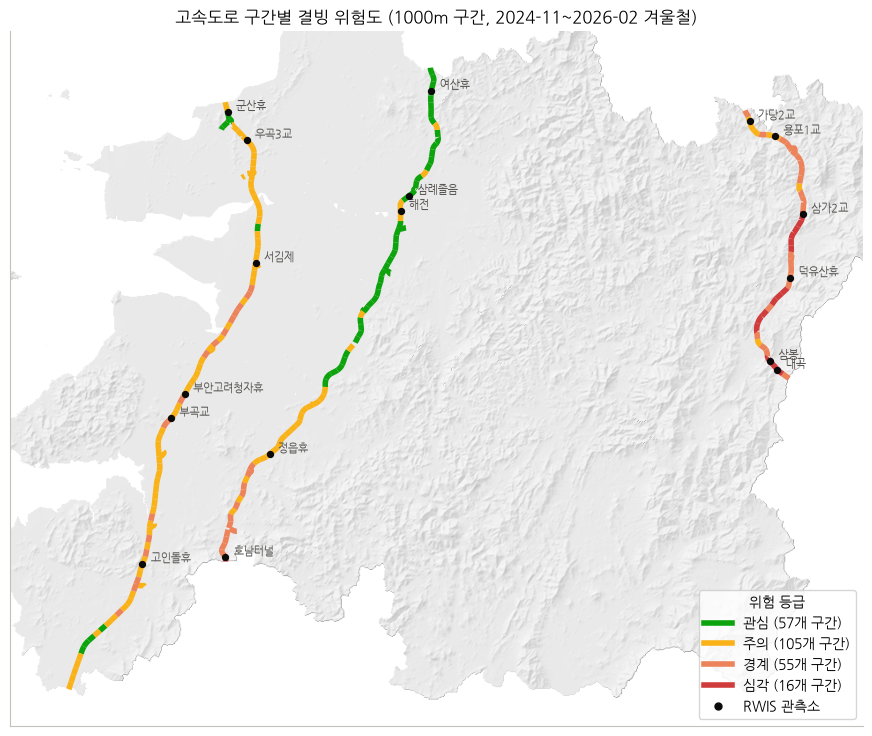

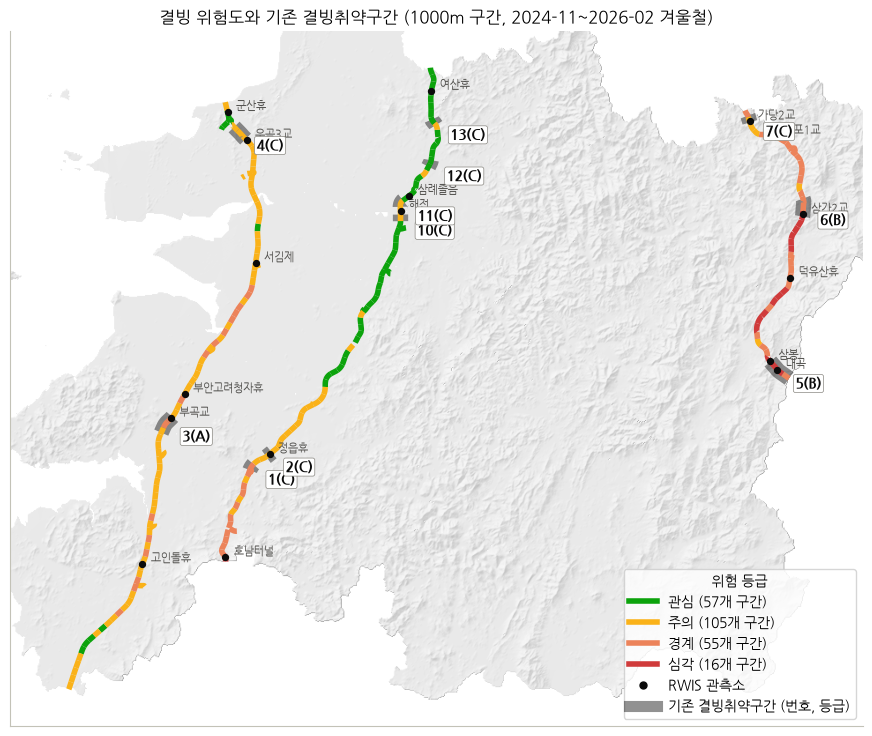

In [13]:
with rasterio.open(config.RAW_DIR / config.RAW_FILES["dem"]) as src:
    step = 4
    dem = src.read(1, out_shape=(src.height // step, src.width // step)).astype(float)
    b = src.bounds
dem[dem < -1000] = np.nan
dem_scale = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["dem_scale"]
gy, gx = np.gradient(np.nan_to_num(dem, nan=0.0) * dem_scale, 30 * step)  # 정규화 DEM → m (02 참고)
slope = np.arctan(np.hypot(gx, gy))
aspect = np.arctan2(-gx, gy)
az, alt = np.radians(315), np.radians(45)
hillshade = np.sin(alt) * np.cos(slope) + np.cos(alt) * np.sin(slope) * np.cos(az - aspect)
hillshade[np.isnan(dem)] = np.nan


def plot_risk_map(scored, path=None, title="고속도로 구간별 결빙 위험도", vulnerable=None):
    """구간별 결빙 위험도 지도 (jpg/png). vulnerable을 주면 기존 결빙취약구간을 함께 그린다."""
    fig, ax = plt.subplots(figsize=(11, 11))
    ax.imshow(hillshade, extent=[b.left, b.right, b.bottom, b.top], cmap="Greys_r", vmin=-0.2, vmax=1.2, alpha=0.35)
    if vulnerable is not None:
        vulnerable.plot(ax=ax, color="#0b0b0b", linewidth=11, alpha=0.45)
    for grade in GRADES:
        part = scored[scored["등급"] == grade]
        if len(part):
            part.plot(ax=ax, color=GRADE_COLORS[grade], linewidth=4)
    st = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(stations["lon"], stations["lat"]), crs=4326)
    st = st.to_crs(scored.crs)
    st.plot(ax=ax, color="#0b0b0b", markersize=18, marker="o", zorder=5)
    for stn, r in st.iterrows():
        ax.annotate(r["name"].replace("(도)", ""), (r.geometry.x, r.geometry.y), xytext=(6, 2),
                    textcoords="offset points", fontsize=8, color="#52514e")
    counts = scored["등급"].value_counts()
    handles = [Line2D([0], [0], color=GRADE_COLORS[g], linewidth=4, label=f"{g} ({counts.get(g, 0)}개 구간)")
               for g in GRADES]
    handles.append(Line2D([0], [0], color="#0b0b0b", marker="o", linestyle="", markersize=5, label="RWIS 관측소"))
    if vulnerable is not None:
        handles.append(Line2D([0], [0], color="#0b0b0b", alpha=0.45, linewidth=8, label="기존 결빙취약구간 (번호, 등급)"))
        for r in vulnerable.itertuples():
            mid = r.geometry.interpolate(0.5, normalized=True)
            ax.annotate(f"{r.no}({r.grade})", (mid.x, mid.y), xytext=(12, -12), textcoords="offset points", fontsize=10,
                        fontweight="bold", color="#0b0b0b", zorder=6,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="#898781", lw=0.5))
    ax.legend(handles=handles, loc="lower right", title="위험 등급", frameon=True)
    xmin, ymin, xmax, ymax = scored.total_bounds
    ax.set_xlim(xmin - 8000, xmax + 8000)
    ax.set_ylim(ymin - 5000, ymax + 5000)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(f"{title} ({config.SEGMENT_LENGTH_M}m 구간, {config.PERIODS[0][0][:7]}~{config.PERIODS[-1][1][:7]} 겨울철)")
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    return fig, ax


fig, ax = plot_risk_map(seg, path=config.FIGURE_DIR / "risk_map.jpg")
fig.savefig(config.FIGURE_DIR / "risk_map.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
plot_risk_map(seg, path=config.FIGURE_DIR / "risk_map_vulnerable.jpg", title="결빙 위험도와 기존 결빙취약구간",
              vulnerable=vuln_lines)
plt.show()

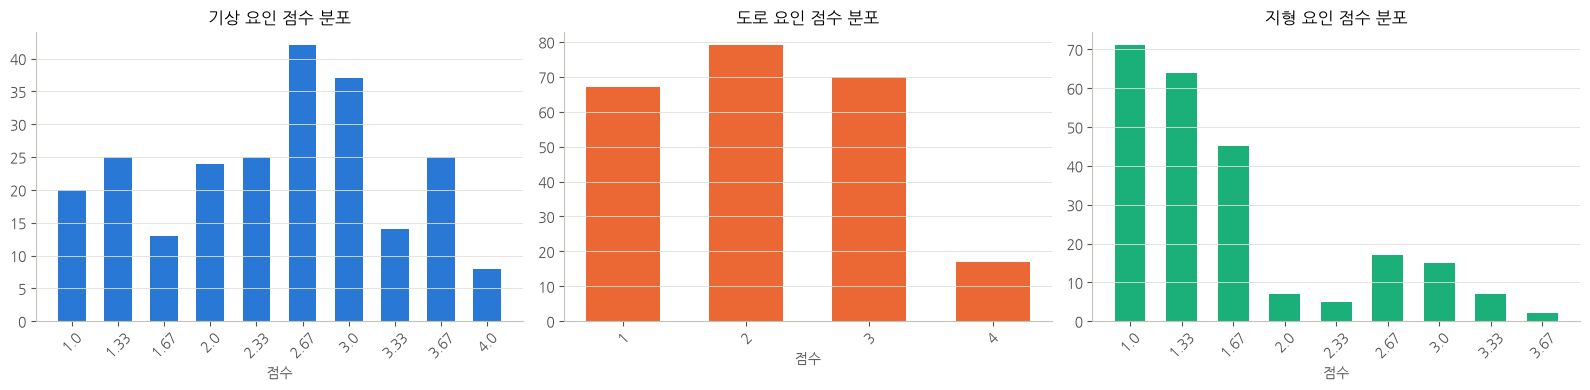

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, factor, color in zip(axes, ["기상", "도로", "지형"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    vals = seg[factor].round(2).value_counts().sort_index()
    ax.bar(vals.index.astype(str), vals.values, color=color, width=0.6)
    ax.set_title(f"{factor} 요인 점수 분포")
    ax.set_xlabel("점수")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [15]:
def export_risk_shapefile(scored, path):
    """구간별 결빙 위험도를 shapefile로 내보낸다 (컬럼명 10자 이내)."""
    m3 = ["frz_snow_hours"] if "frz_snow_hours" in scored else []
    out = scored.reset_index()[["seg_id", "route", "length_m", "elev", "bridge_ratio", "shade_winter",
                                "icing_cond_hours", "icing_pred_hours", *m3, "rst_night_mean",
                                "기상", "도로", "지형", "총점", "등급", "geometry"]]
    out = out.rename(columns={"length_m": "length", "bridge_ratio": "bridge_r", "shade_winter": "shade",
                              "icing_cond_hours": "cond_h", "icing_pred_hours": "pred_h", "frz_snow_hours": "frz_h",
                              "rst_night_mean": "rst_night", "기상": "s_meteo", "도로": "s_road",
                              "지형": "s_terrain", "총점": "score", "등급": "grade"})
    out["grade"] = out["grade"].astype(str)
    out["grade_lv"] = out["grade"].map({g: i + 1 for i, g in enumerate(GRADES)})
    out = gpd.GeoDataFrame(out.round(3), geometry="geometry", crs=scored.crs)
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_file(path, driver="ESRI Shapefile", encoding="utf-8")
    return out


shp = export_risk_shapefile(seg, config.FIGURE_DIR / "risk_map_shp" / "segment_risk.shp")
vuln_shp = vuln_lines.merge(vuln[["no", "status", "matched_km", "평균 총점", "최고 등급", "경계·심각 비율"]], on="no").rename(
    columns={"length_km": "length", "matched_km": "match_km", "평균 총점": "score", "최고 등급": "grade_max", "경계·심각 비율": "high_r"})
vuln_shp.round(3).to_file(config.FIGURE_DIR / "risk_map_shp" / "vulnerable_sections.shp", driver="ESRI Shapefile",
                          encoding="utf-8")
print(shp.shape, sorted(p.name for p in (config.FIGURE_DIR / "risk_map_shp").iterdir()))

(233, 17) ['segment_risk.cpg', 'segment_risk.dbf', 'segment_risk.prj', 'segment_risk.shp', 'segment_risk.shx', 'vulnerable_sections.cpg', 'vulnerable_sections.dbf', 'vulnerable_sections.prj', 'vulnerable_sections.shp', 'vulnerable_sections.shx']


확대와 이동이 가능한 웹 지도(html)도 만듭니다. 구간을 누르면 요인별 점수가 나오고 기존 결빙취약구간은 검은 점선으로 표시됩니다.

In [16]:
web = seg.reset_index().to_crs(4326)
web["등급"] = web["등급"].astype(str)
fmap = folium.Map(location=[35.78, 127.1], zoom_start=9, tiles="CartoDB positron")
folium.GeoJson(
    web[["seg_id", "route", "등급", "총점", "기상", "도로", "지형", "elev", "bridge_ratio", "geometry"]].round(2),
    style_function=lambda f: {"color": GRADE_COLORS[f["properties"]["등급"]], "weight": 6, "opacity": 0.9},
    tooltip=folium.GeoJsonTooltip(fields=["seg_id", "route", "등급", "총점", "기상", "도로", "지형", "elev", "bridge_ratio"],
                                  aliases=["구간", "노선", "등급", "총점", "기상", "도로", "지형", "표고(m)", "교량 비율"]),
).add_to(fmap)
folium.GeoJson(
    vuln_lines.merge(vuln[["no", "status"]], on="no").to_crs(4326)[["no", "road", "km_from", "km_to", "grade", "status", "geometry"]],
    style_function=lambda f: {"color": "#0b0b0b", "weight": 3, "dashArray": "6 6"},
    tooltip=folium.GeoJsonTooltip(fields=["no", "road", "km_from", "km_to", "grade", "status"],
                                  aliases=["기존 취약구간", "노선", "시점(km)", "종점(km)", "등급", "비교"]),
).add_to(fmap)
legend = "".join(f"<div><span style='display:inline-block;width:14px;height:6px;background:{GRADE_COLORS[g]};"
                 f"margin-right:6px'></span>{g}</div>" for g in GRADES)
legend += "<div>검은 점선: 기존 결빙취약구간</div>"
fmap.get_root().html.add_child(folium.Element(
    f"<div style='position:fixed;bottom:24px;left:24px;z-index:9999;background:white;padding:8px 10px;"
    f"border:1px solid #c3c2b7;font-size:13px'><b>결빙 위험 등급</b>{legend}</div>"))
fmap.save(config.FIGURE_DIR / "risk_map.html")

결과 CSV를 저장합니다.

In [17]:
criteria.to_csv(config.RESULT_DIR / "risk_criteria.csv", index=False, encoding="utf-8-sig")
(vuln.assign(segments=vuln["segments"].map(" ".join)).round(3)
 .rename(columns={"no": "연번", "branch": "관리기관", "road": "노선명", "km_from": "시점(km)", "km_to": "종점(km)",
                  "length_km": "연장(km)", "grade": "기존 등급", "status": "비교 상태", "matched_km": "비교 길이(km)",
                  "segments": "연결 구간"})
 .drop(columns="route").to_csv(config.RESULT_DIR / "vulnerable_comparison.csv", index=False, encoding="utf-8-sig"))
with open(config.RESULT_DIR / "vulnerable_summary.json", "w", encoding="utf-8") as f:
    json.dump({"sections": len(compared), "segments": len(ids), "high_share_in_sections": round(float(observed), 3),
               "high_share_all": round(float(seg["등급"].isin(HIGH).mean()), 3),
               "random_placement_mean": round(float(null.mean()), 3),
               "random_placement_p": round(float((null >= observed).mean()), 3),
               "by_route": by_route.reset_index().to_dict("records")}, f, ensure_ascii=False, indent=1)
(seg.drop(columns="geometry").reset_index()
 [["seg_id", "route", "on_mainline", "length_m", "lon", "lat", "elev", "tpi", "shade_winter", "dist_river", "bridge_ratio",
   "tunnel_ratio", "seg_dist_tunnel", "curve_radius_m", "rst_mean", "rst_night_mean", "rst_le0_hours", "icing_cond_hours",
   "icing_pred_hours", *(["frz_snow_hours"] if USE_M3 else []), "M1", "M2", *(["M3"] if USE_M3 else []),
   "R1", "R2", "T1", "T2", "T3", "기상", "도로", "지형", "총점", "등급"]]
 .round(3).to_csv(config.RESULT_DIR / "segment_risk.csv", index=False, encoding="utf-8-sig"))
seg_feat[["seg_id", "time", "rst_est", "p_icing"]].round(3).to_parquet(
    config.RESULT_DIR / "segment_estimates_hourly.parquet", index=False)
for p in sorted(config.RESULT_DIR.iterdir()):
    print(f"{p.name:36s} {p.stat().st_size / 1e3:9.1f} KB")

estimation_cv_scores.csv                   7.3 KB
estimation_ensembles.csv                   0.4 KB
estimation_era5_b3.csv                     0.5 KB
estimation_holdout_10min.csv            3718.9 KB
estimation_interp_ensembles.csv            0.8 KB
estimation_interp_fingerprints.csv         1.0 KB
estimation_interp_ladder.csv               1.9 KB
estimation_mlp_architectures.csv           1.3 KB
estimation_model_comparison.csv            1.2 KB
estimation_scores.csv                      2.7 KB
estimation_site_correction.csv             2.9 KB
external_check_icing_ablation.csv          3.8 KB
external_check_m3_grades.csv              21.1 KB
holdout_submission_10min.csv            7538.7 KB
icing_10min_scores.csv                     0.2 KB
icing_conditions.csv                       0.2 KB
icing_cv_scores.csv                        0.4 KB
icing_daily_scores.csv                    28.6 KB
icing_ensembles.csv                        0.6 KB
icing_era5_ablation.csv                    1.0 KB
